In [1]:
# Figure 2 depth/loop experiment (baseline and shared-weight looped transformer)

import torch
from matplotlib import pyplot as plt
import sys
import time
import os
import numpy as np

# Use CUDA when available, otherwise CPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
from linear_transformer import (
    Transformer_F,
    Transformer_F_Looped,
    attention,
    generate_data,
    in_context_loss,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)
print(f'Running on device: {device}.')

Running on device: cuda.


In [2]:
# Set up problem parameters

lr = 0.001
clip_r = 1000
alg = 'adam'
mode = 'normal'

N = 10     # context length (no assumption given in paper)
d = 5        # dimension

n_head = 1  # 1-headed attention
B = 4000  # 4000 minibatch size
var = 0.05  # initializations scale of transformer parameter
shape_k = 0.1  # shape_k: parameter for Gamma distributed covariates
max_iters = 10000  # Number of Iterations to run
hist_stride = 1  # stride for saved model paramters in `train.ipynb'
stride = 100

# a convenience function for taking a step and clipping
def clip_and_step(allparam, optimizer, clip_r = None):
    norm_p=None
    grad_all = allparam.grad
    if clip_r is not None:
        norm_p = grad_all.norm().item()

        if norm_p > clip_r:
            grad_all.mul_(clip_r/norm_p)
    optimizer.step()
    return norm_p

In [5]:
####################################
# train layered and shared-weight looped transformers
####################################

filename_format = '/figure_two_layers_vs_loops_{}_{}.pth'
filename = cur_dir + filename_format.format(N, d)

seeds = [0, 1, 2]
n_layers_loops = [1, 2, 5, 10]
model_types = ['layered', 'looped']
keys = [(seed, count, model_type)
        for seed in seeds
        for count in n_layers_loops
        for model_type in model_types]

hist_dict = {}
for run_index, key in enumerate(keys, start=1):
    seed, count, model_type = key
    print(f'Run {run_index}/{len(keys)}: seed={seed}, count={count}, type={model_type}')
    hist_dict[key] = []

    torch.manual_seed(seed)
    if model_type == 'layered':
        model = Transformer_F(count, n_head, d, var)
    else:
        model = Transformer_F_Looped(count, n_head, d, var)
    model = model.to(device)

    if alg == 'sgd':
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=0)
    elif alg == 'adam':
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.9), weight_decay=0)
    else:
        raise ValueError(f'Unsupported optimizer: {alg}')

    np.random.seed(seed)
    torch.manual_seed(seed)
    for t in range(max_iters):
        start = time.time()
        if t % hist_stride == 0:
            hist_dict[key].append(model.allparam.detach().clone())

        Z, y = generate_data(mode, N, d, B, shape_k)
        Z = Z.to(device)
        y = y.to(device)
        loss = in_context_loss(model, Z, y)
        loss.backward()
        grad_norm = clip_and_step(model.allparam, optimizer, clip_r=clip_r)

        if not np.isfinite(grad_norm):
            print(f'Stopping early: non-finite gradient norm at iteration {t}.')
            optimizer.zero_grad()
            break

        optimizer.zero_grad()
        end = time.time()
        if t % 100 == 0 or t < 5:
            print(f'iter {t} | Loss: {loss.item()} | time: {end-start} | gradnorm: {grad_norm}')

    print(f'Finished seed={seed}, count={count}, type={model_type}.')

torch.save({'hist_dict': hist_dict}, filename)
print(f'Saved histories to {filename}')

Run 1/24: seed=0, count=1, type=layered
iter 0 | Loss: 5.583387851715088 | time: 0.0061283111572265625 | gradnorm: 4.943443298339844
iter 1 | Loss: 5.09586238861084 | time: 0.004993438720703125 | gradnorm: 4.565327167510986
iter 2 | Loss: 5.328909873962402 | time: 0.0060596466064453125 | gradnorm: 4.799430847167969
iter 3 | Loss: 5.160664081573486 | time: 0.0048902034759521484 | gradnorm: 4.6755194664001465
iter 4 | Loss: 5.127560138702393 | time: 0.0048656463623046875 | gradnorm: 4.502877712249756
iter 100 | Loss: 4.155155658721924 | time: 0.002507925033569336 | gradnorm: 3.831400156021118
iter 200 | Loss: 3.590285062789917 | time: 0.0024302005767822266 | gradnorm: 3.3312251567840576
iter 300 | Loss: 2.9695944786071777 | time: 0.0029938220977783203 | gradnorm: 2.7237231731414795
iter 400 | Loss: 2.45053768157959 | time: 0.0024449825286865234 | gradnorm: 1.9503016471862793
iter 500 | Loss: 2.0841314792633057 | time: 0.0024406909942626953 | gradnorm: 1.3367317914962769
iter 600 | Loss: 

In [6]:
####################################
# compute test loss for available layered and looped checkpoints
####################################

TEST_SEED = 99
hist_dict = torch.load(filename, map_location='cpu')['hist_dict']
loss_dict = {}

for key, history in hist_dict.items():
    seed, count, model_type = key
    test_losses = torch.full((len(range(0, max_iters, stride)),), float('nan'))

    np.random.seed(TEST_SEED)
    torch.manual_seed(TEST_SEED)
    Z, y = generate_data(mode, N, d, B, shape_k)
    Z = Z.to(device)
    y = y.to(device)
    if model_type == 'layered':
        model = Transformer_F(count, n_head, d, var).to(device)
    else:
        model = Transformer_F_Looped(count, n_head, d, var).to(device)

    for iteration in range(0, max_iters, stride):
        if iteration % hist_stride != 0:
            continue
        history_index = iteration // hist_stride
        if history_index >= len(history):
            break
        snapshot = history[history_index]
        if not torch.isfinite(snapshot).all():
            continue

        with torch.no_grad():
            model.allparam.copy_(snapshot.to(device))
            test_losses[iteration // stride] = in_context_loss(model, Z, y).item()

    loss_dict[key] = test_losses

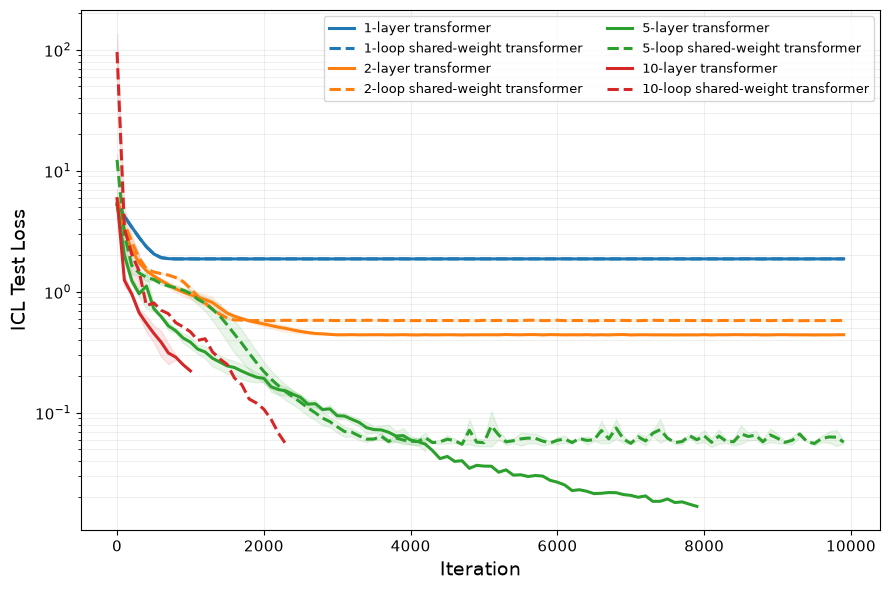

In [7]:
####################################
# integrated test-loss comparison: layered vs shared-weight looped
####################################

fig_dir = 'figures'
os.makedirs(fig_dir, exist_ok=True)
fig, ax = plt.subplots(1, 1, figsize=(9, 6))
iterations = np.arange(0, max_iters, stride)
colors = dict(zip(n_layers_loops, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']))

for count in n_layers_loops:
    for model_type, line_style, label in (
        ('layered', '-', f'{count}-layer transformer'),
        ('looped', '--', f'{count}-loop shared-weight transformer'),
    ):
        run_keys = [key for key in loss_dict if key[1] == count and key[2] == model_type]
        if not run_keys:
            continue
        run_losses = torch.stack([loss_dict[key] for key in run_keys])
        valid = torch.isfinite(run_losses)
        n_valid = valid.sum(dim=0)
        safe_losses = torch.where(valid, run_losses, torch.zeros_like(run_losses))
        mean_loss = safe_losses.sum(dim=0) / n_valid.clamp_min(1)
        mean_loss[n_valid == 0] = float('nan')

        variance = torch.where(
            valid,
            (run_losses - mean_loss.unsqueeze(0)) ** 2,
            torch.zeros_like(run_losses),
        ).sum(dim=0) / n_valid.clamp_min(1)
        std_loss = variance.sqrt()
        ax.plot(
            iterations, mean_loss.numpy(), color=colors[count], linestyle=line_style,
            lw=2.2, label=label,
        )
        multiple = n_valid > 1
        lower = torch.where(multiple, mean_loss - std_loss, torch.nan)
        upper = torch.where(multiple, mean_loss + std_loss, torch.nan)
        ax.fill_between(
            iterations, lower.numpy(), upper.numpy(),
            color=colors[count], alpha=0.10,
        )

ax.set_xlabel('Iteration', fontsize=14)
ax.set_ylabel('ICL Test Loss', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.set_yscale('log')
ax.legend(fontsize=9, ncol=2)
ax.grid(True, which='both', alpha=0.2)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'figure_two_test_loss_layered_vs_looped.pdf'), dpi=600)
plt.show()

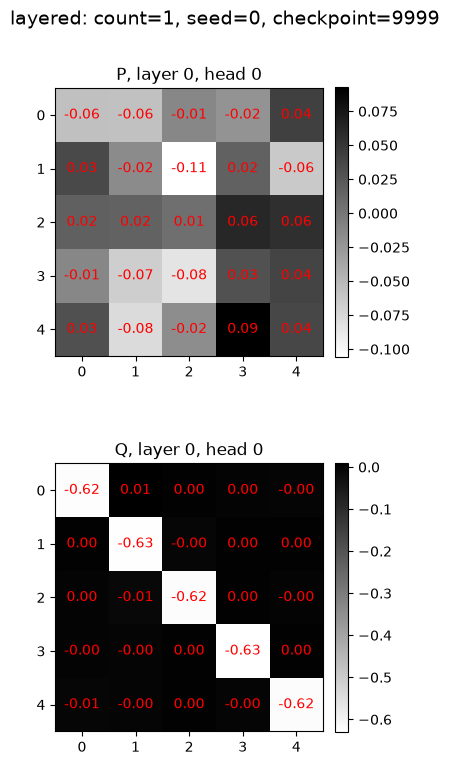

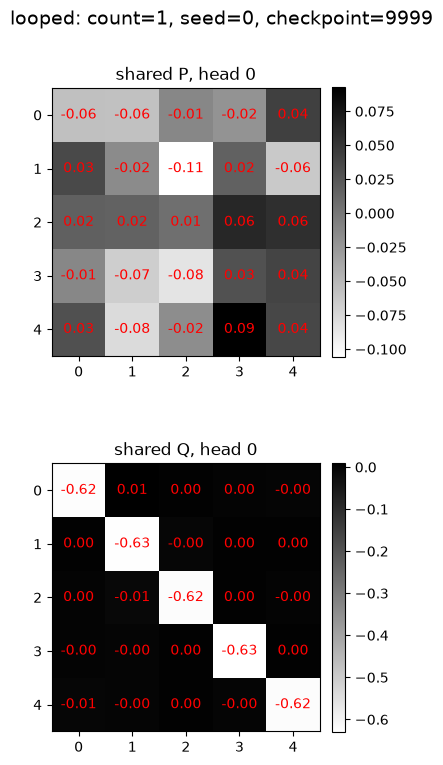

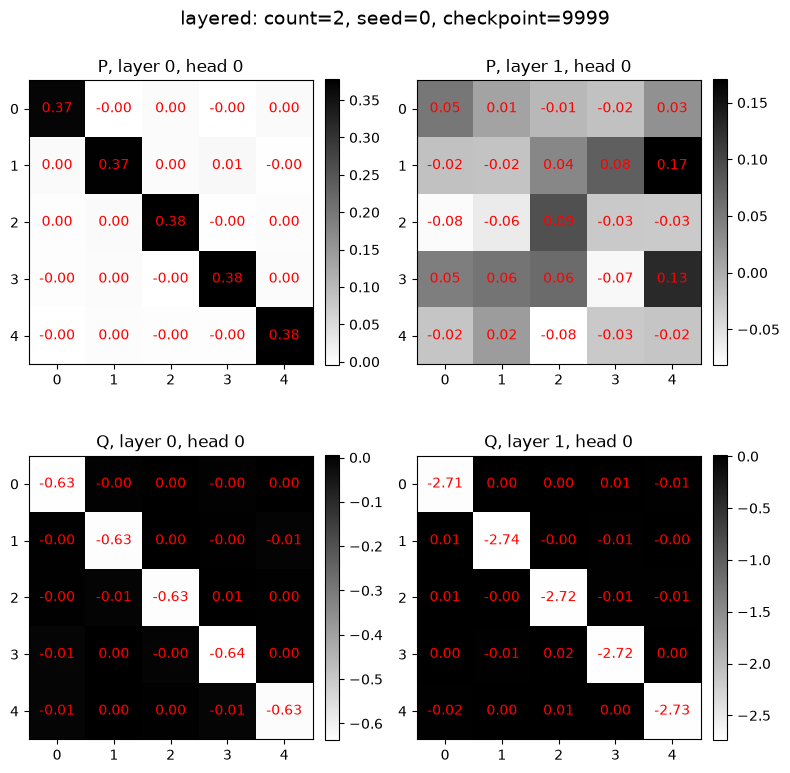

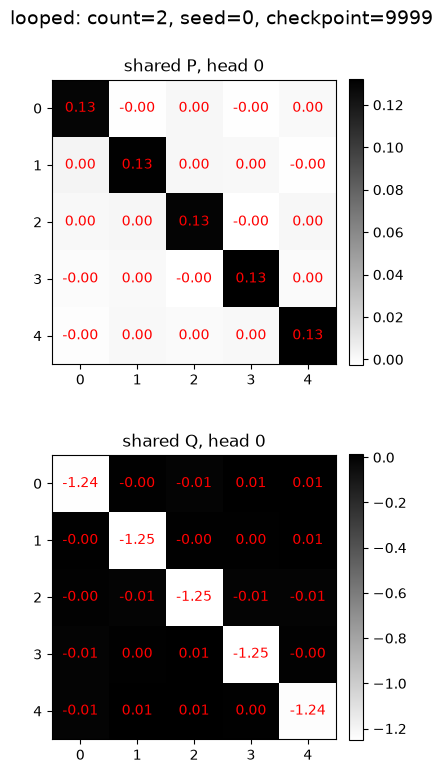

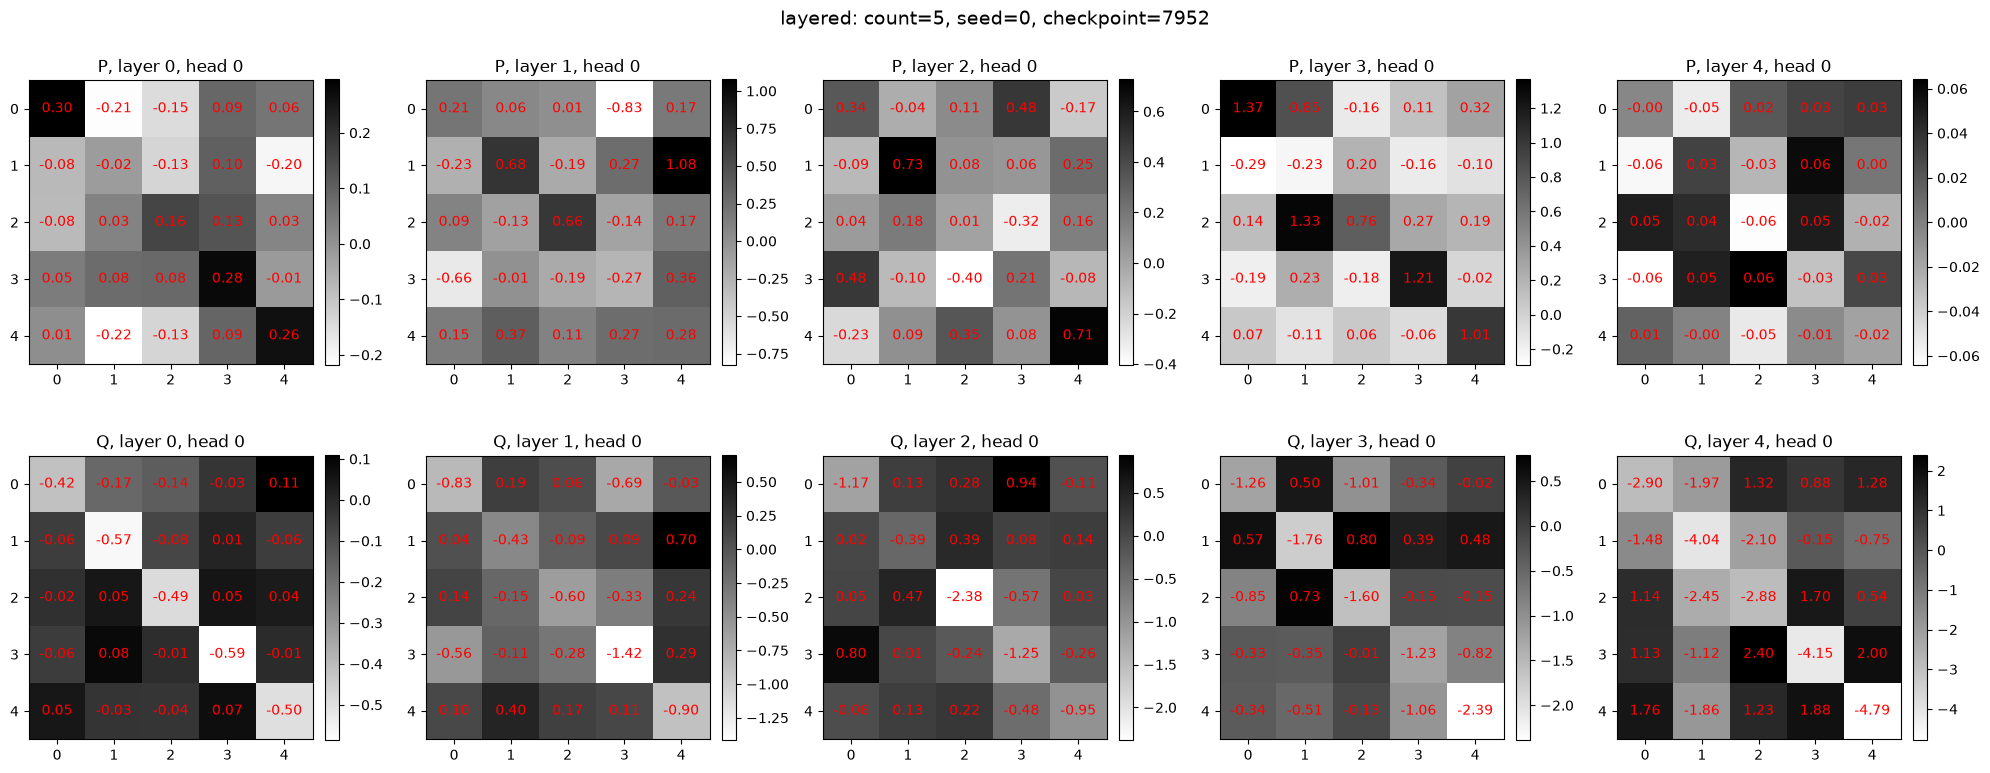

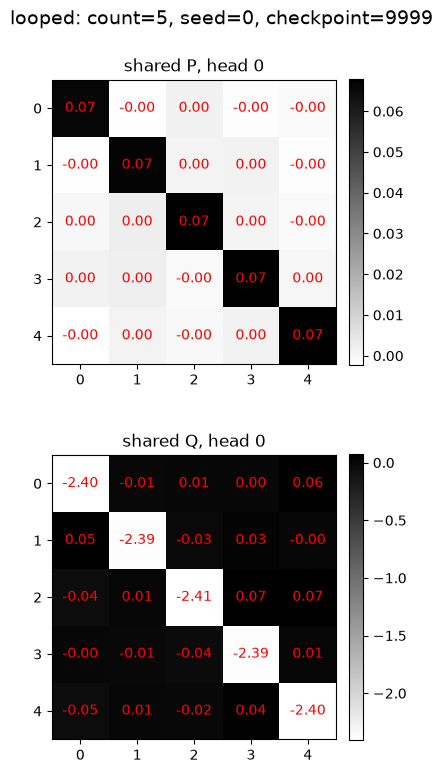

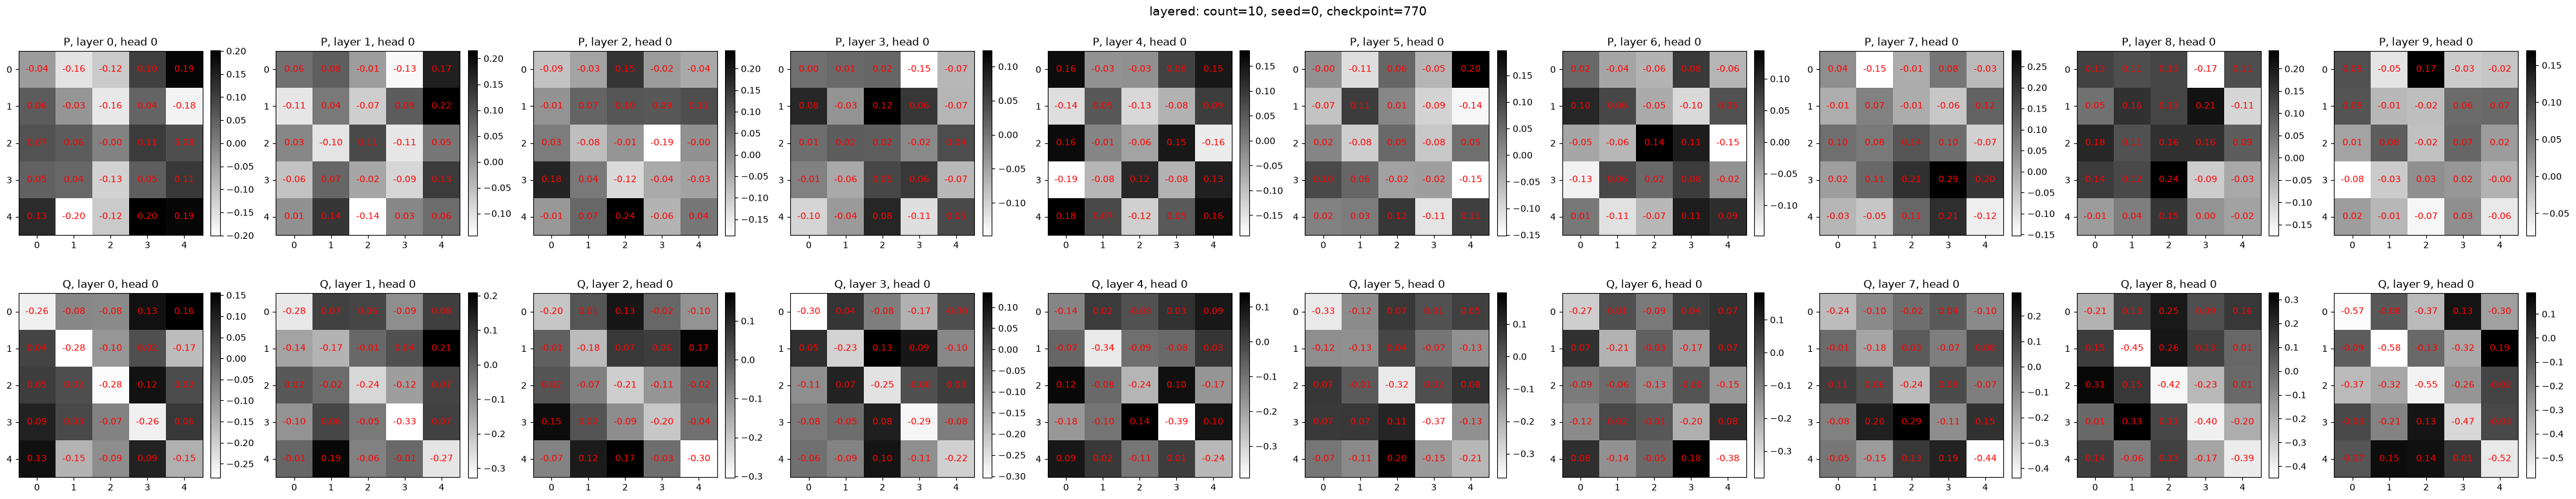

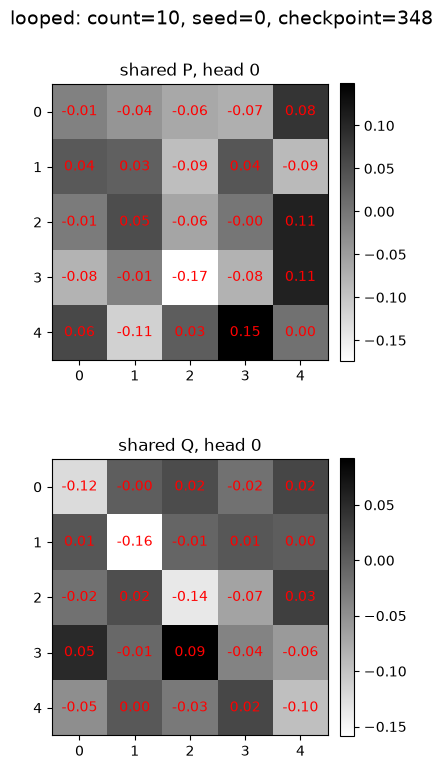

In [8]:
####################################
# parameter matrices for both architectures
# layered models have a separate block per layer; looped models share one block
####################################

plot_seed = seeds[0]
for count in n_layers_loops:
    for model_type in model_types:
        key = (plot_seed, count, model_type)
        if key not in hist_dict:
            print(f'No saved run found for {key}; skipping parameter plot.')
            continue
        history = hist_dict[key]
        snapshot_index = next(
            (idx for idx in range(len(history) - 1, -1, -1)
             if torch.isfinite(history[idx]).all()),
            None,
        )
        if snapshot_index is None:
            print(f'No finite checkpoint found for {key}; skipping parameter plot.')
            continue

        snapshot = history[snapshot_index].detach().cpu()
        block_count = snapshot.shape[0]
        fig, axs = plt.subplots(
            2 * n_head, block_count,
            figsize=(4 * block_count, 4 * 2 * n_head),
            squeeze=False,
        )

        for head in range(n_head):
            for block in range(block_count):
                for matrix_type, matrix_name in enumerate(('P', 'Q')):
                    ax = axs[matrix_type * n_head + head, block]
                    matrix = snapshot[block, head, matrix_type]
                    im = ax.imshow(matrix, cmap='gray_r')
                    for row in range(matrix.shape[0]):
                        for col in range(matrix.shape[1]):
                            ax.text(col, row, f'{matrix[row, col].item():.2f}',
                                    ha='center', va='center', color='r')
                    if model_type == 'looped':
                        title = f'shared {matrix_name}, head {head}'
                    else:
                        title = f'{matrix_name}, layer {block}, head {head}'
                    ax.set_title(title)
                    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        fig.suptitle(
            f'{model_type}: count={count}, seed={plot_seed}, '
            f'checkpoint={snapshot_index * hist_stride}',
            fontsize=14,
        )
        fig.tight_layout()
        fig.savefig(
            os.path.join(fig_dir, f'figure_two_parameters_{model_type}_count{count}_seed{plot_seed}.pdf'),
            dpi=600,
            bbox_inches='tight',
        )
        plt.show()

In [9]:
########################################################
# compute distance-to-identity for both architectures
########################################################

def compute_dist_identity(M):
    scale = torch.diagonal(M).sum() / M.shape[0]
    ideal_identity = scale * torch.eye(M.shape[0], device=M.device, dtype=M.dtype)
    denominator = torch.linalg.norm(M, ord='fro')
    if not torch.isfinite(denominator) or denominator == 0:
        return float('nan')
    return (torch.linalg.norm(M - ideal_identity, ord='fro') / denominator).item()

# Store per-run distances as (count, P/Q, checkpoints). For looped models,
# the shared block is repeated across loop positions for a direct comparison.
dist_dict = {}
iterations = np.arange(0, max_iters, stride)

for key, history in hist_dict.items():
    seed, count, model_type = key
    distances = torch.full((count, 2, len(iterations)), float('nan'))

    for point_index, iteration in enumerate(iterations):
        if iteration % hist_stride != 0:
            continue
        history_index = iteration // hist_stride
        if history_index >= len(history):
            break
        snapshot = history[history_index]
        if not torch.isfinite(snapshot).all():
            continue

        parameter_blocks = snapshot.shape[0]
        for block in range(count):
            source_block = block if model_type == 'layered' else 0
            for matrix_type in range(2):
                head_distances = [
                    compute_dist_identity(snapshot[source_block, head, matrix_type])
                    for head in range(n_head)
                ]
                finite_distances = [value for value in head_distances if np.isfinite(value)]
                if finite_distances:
                    distances[block, matrix_type, point_index] = float(np.mean(finite_distances))

    dist_dict[key] = distances

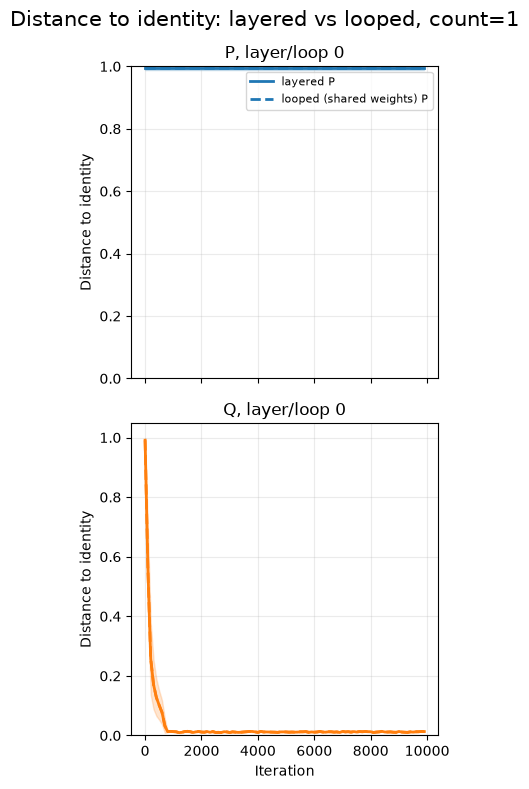

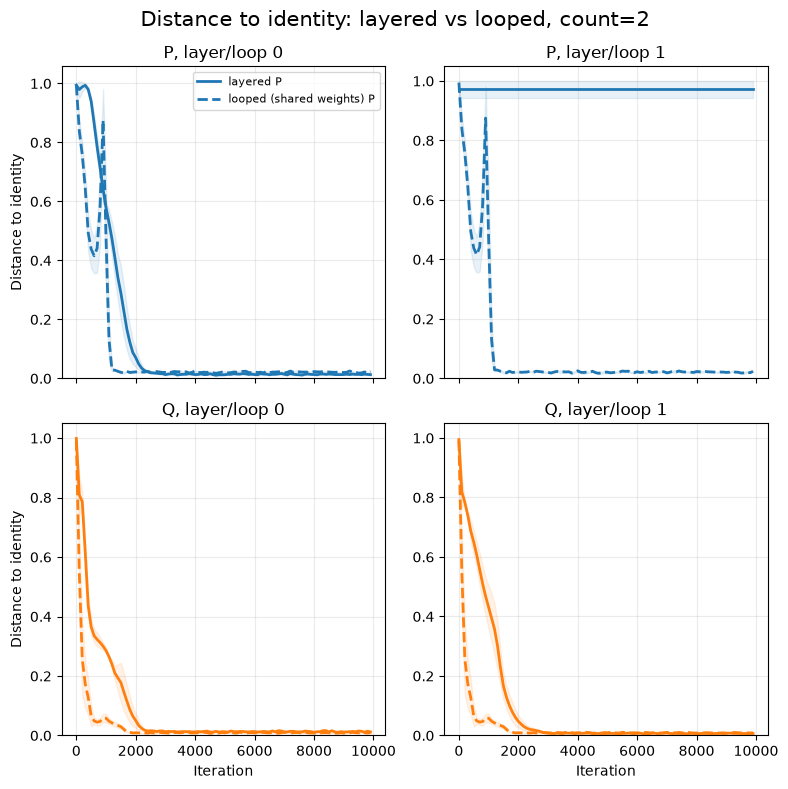

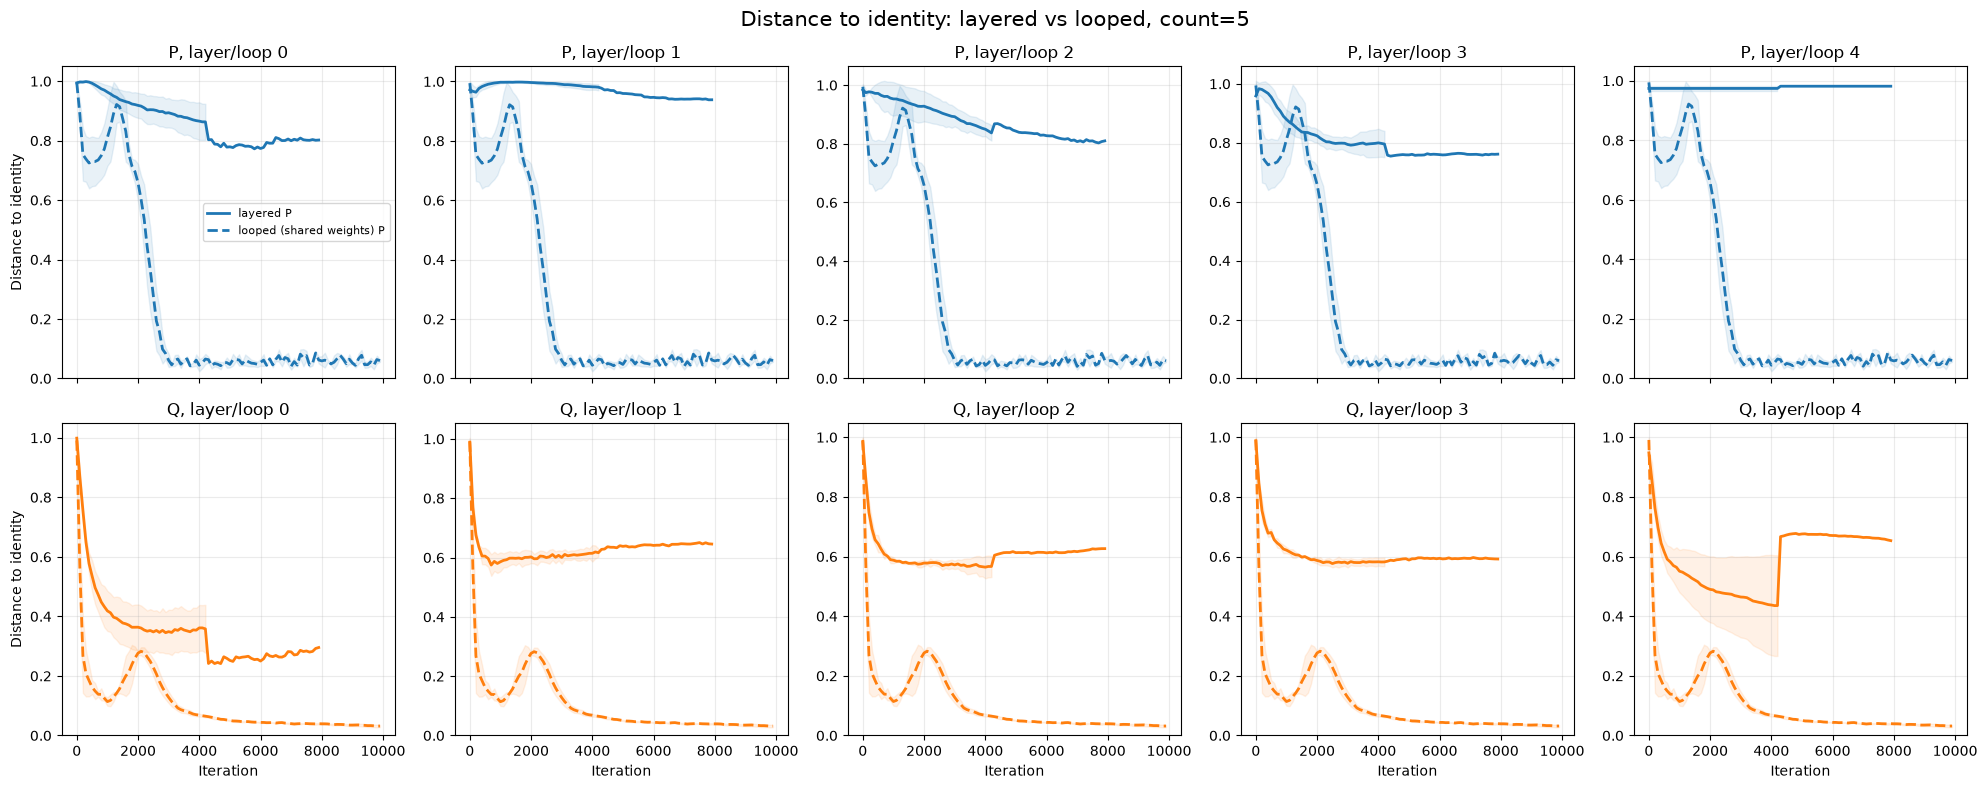

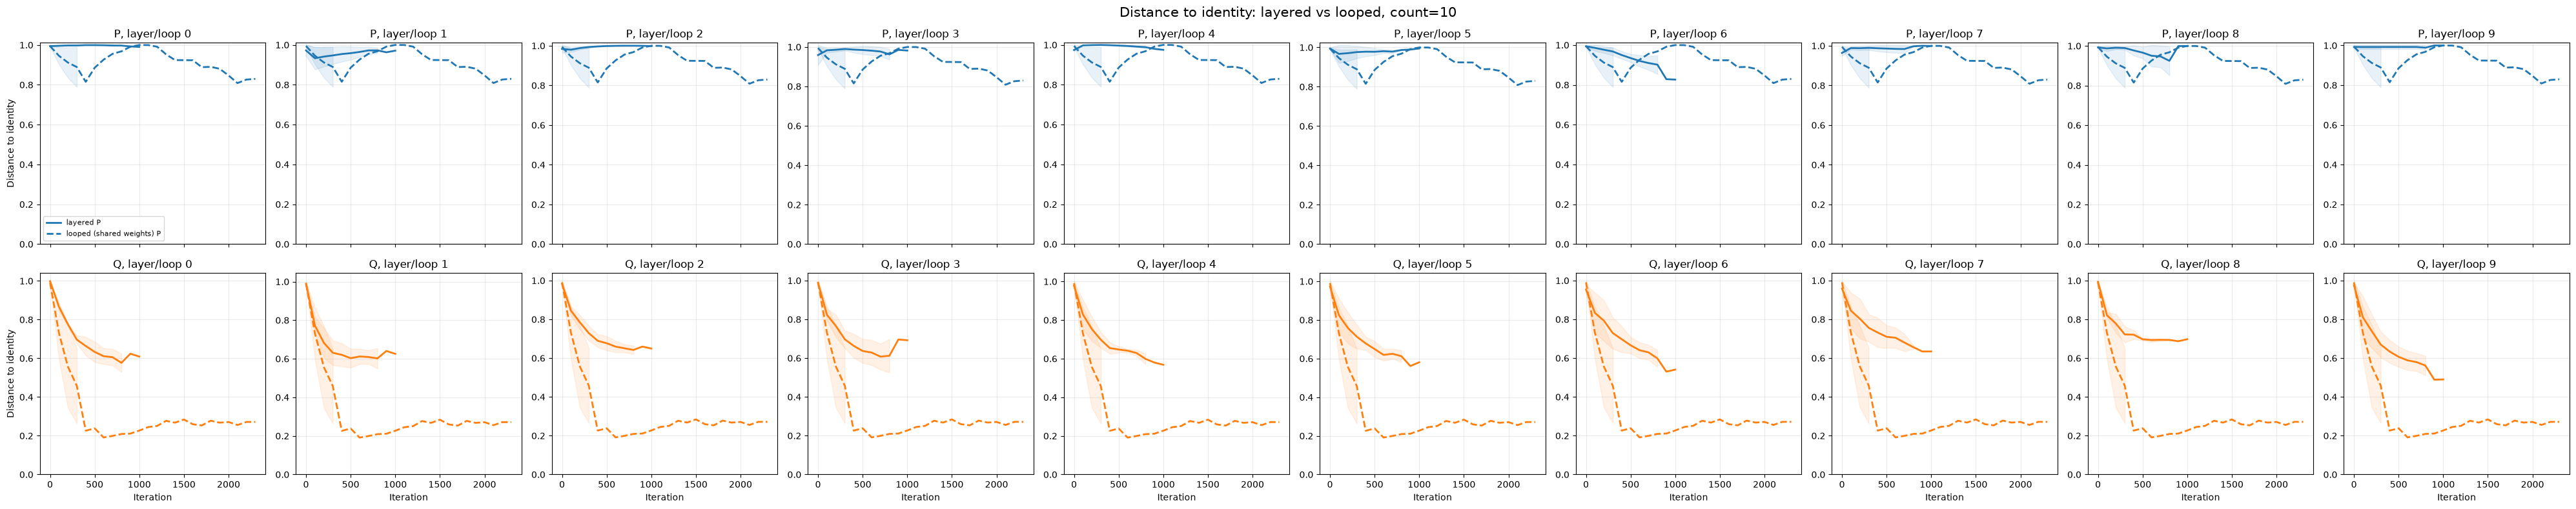

In [10]:
########################################################
# integrated distance-to-identity comparison by depth/loop count
########################################################

for count in n_layers_loops:
    fig, axs = plt.subplots(
        2, count,
        figsize=(4 * count, 8),
        squeeze=False,
        sharex=True,
    )

    for matrix_type, matrix_name in enumerate(('P', 'Q')):
        for block in range(count):
            ax = axs[matrix_type, block]
            for model_type, line_style, label in (
                ('layered', '-', 'layered'),
                ('looped', '--', 'looped (shared weights)'),
            ):
                run_keys = [
                    key for key in dist_dict
                    if key[1] == count and key[2] == model_type
                ]
                if not run_keys:
                    continue

                seed_curves = torch.stack([
                    dist_dict[key][block, matrix_type] for key in run_keys
                ])
                valid = torch.isfinite(seed_curves)
                n_valid = valid.sum(dim=0)
                values = torch.where(valid, seed_curves, torch.zeros_like(seed_curves))
                mean = values.sum(dim=0) / n_valid.clamp_min(1)
                mean[n_valid == 0] = float('nan')
                variance = torch.where(
                    valid,
                    (seed_curves - mean.unsqueeze(0)) ** 2,
                    torch.zeros_like(seed_curves),
                ).sum(dim=0) / n_valid.clamp_min(1)
                std = variance.sqrt()

                color = 'tab:blue' if matrix_type == 0 else 'tab:orange'
                ax.plot(
                    iterations, mean.numpy(), color=color, linestyle=line_style,
                    lw=2, label=f'{label} {matrix_name}',
                )
                multiple = n_valid > 1
                lower = torch.where(multiple, mean - std, torch.nan)
                upper = torch.where(multiple, mean + std, torch.nan)
                ax.fill_between(
                    iterations, lower.numpy(), upper.numpy(),
                    color=color, alpha=0.10,
                )

            ax.set_title(f'{matrix_name}, layer/loop {block}')
            ax.set_ylim(bottom=0)
            ax.grid(True, alpha=0.25)
            if matrix_type == 0 and block == 0:
                ax.legend(fontsize=8)

    for ax in axs[-1, :]:
        ax.set_xlabel('Iteration')
    axs[0, 0].set_ylabel('Distance to identity')
    axs[1, 0].set_ylabel('Distance to identity')
    fig.suptitle(f'Distance to identity: layered vs looped, count={count}', fontsize=15)
    fig.tight_layout()
    fig.savefig(
        os.path.join(fig_dir, f'figure_two_dist_to_identity_count{count}.pdf'),
        dpi=600,
        bbox_inches='tight',
    )
    plt.show()